# PROYEK AKHIR MATA KULIAH PROBABILITAS DAN STATISTIKA
## "Analisis dan Pengelompokan Karakteristik Keterlambatan Penerbangan Berdasarkan Durasi Keterlambatan dan Jarak Tempuh Menggunakan Metode K-Means"

* **Kelas / Kelompok:** 3TI A — Kelompok 3
* **Konsentrasi Bidang TI:** Jaringan / IoT - Open Source & Cloud Networking (OSCN)
* **Program Studi:** Sarjana Terapan Teknik Informatika, Politeknik Caltex Riau (PCR)
* **Dosen Pengampu:** Mona Elviyenti, S.Si., M.Si.
* **Anggota Tim:**
  1. Hanif Andika Hizamil Putra (NIM: 2455301079)
  2. Yuma Wisesa Jigme (NIM: 2455301199)
  3. Aditya Cahyo Oktavian (NIM: 2455301008)
  4. Arkan Fawwaz Safii (NIM: 2455301031)


In [18]:
# ==========================================
# KHUSUS GOOGLE COLAB / JUPYTER BARU:
# Instal pustaka python-calamine untuk membaca Excel raksasa (100MB) dalam hitungan detik
# ==========================================
!pip install -q python-calamine


In [19]:
# ==========================================
# 0. IMPORT LIBRARY DAN KONFIGURASI VISUAL
# ==========================================
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')

# Konfigurasi gaya visualisasi profesional
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['figure.dpi'] = 120

print('✅ Seluruh pustaka (libraries) berhasil diimpor dengan konfigurasi visual aktif.')


✅ Seluruh pustaka (libraries) berhasil diimpor dengan konfigurasi visual aktif.


---
### 1. Memuat Dataset dan Menampilkan Sampel Data Awal (100 Baris)
Dataset operasional penerbangan dimuat dari berkas `3TIA_03_FlightDelay.xlsx`. Untuk efisiensi pembacaan berkas 100MB, digunakan engine `calamine` (dengan *fallback* otomatis ke default jika belum terpasang). Sebagai langkah inspeksi awal, ditampilkan ukuran dataset dan pratinjau 100 baris pertama sampel data.


In [20]:
# ==========================================
# 1. LOAD DATASET & PRATINJAU 100 SAMPEL DATA
# ==========================================
# Membaca berkas Excel (menggunakan engine calamine untuk kecepatan tinggi, fallback otomatis)
try:
    import python_calamine
    df_raw = pd.read_excel('3TIA_03_FlightDelay.xlsx', engine='calamine')
    print('✅ Berkas berhasil dibaca menggunakan engine calamine.')
except (ImportError, ModuleNotFoundError):
    print('⚠️ Modul python_calamine belum terpasang. Membaca dengan engine standar...')
    df_raw = pd.read_excel('3TIA_03_FlightDelay.xlsx')

print(f'Dimensi dataset mentah: {df_raw.shape[0]:,} baris x {df_raw.shape[1]} kolom')
print(f'Daftar kolom yang tersedia:\n{df_raw.columns.tolist()}\n')

# Menampilkan 100 baris pertama sesuai ketentuan sampel awal
df_sample_100 = df_raw.head(100)
print('Pratinjau 100 baris pertama sampel data (menampilkan 6 kolom representatif):')
df_sample_100[['FL_DATE', 'OP_CARRIER', 'ORIGIN', 'DEST', 'ARR_DELAY', 'DISTANCE']].head(10)


✅ Berkas berhasil dibaca menggunakan engine calamine.
Dimensi dataset mentah: 1,048,575 baris x 27 kolom
Daftar kolom yang tersedia:
['FL_DATE', 'OP_CARRIER', 'OP_CARRIER_FL_NUM', 'ORIGIN', 'DEST', 'CRS_DEP_TIME', 'DEP_TIME', 'DEP_DELAY', 'TAXI_OUT', 'WHEELS_OFF', 'WHEELS_ON', 'TAXI_IN', 'CRS_ARR_TIME', 'ARR_TIME', 'ARR_DELAY', 'CANCELLED', 'CANCELLATION_CODE', 'DIVERTED', 'CRS_ELAPSED_TIME', 'ACTUAL_ELAPSED_TIME', 'AIR_TIME', 'DISTANCE', 'CARRIER_DELAY', 'WEATHER_DELAY', 'NAS_DELAY', 'SECURITY_DELAY', 'LATE_AIRCRAFT_DELAY']

Pratinjau 100 baris pertama sampel data (menampilkan 6 kolom representatif):


,FL_DATE,OP_CARRIER,ORIGIN,DEST,ARR_DELAY,DISTANCE
0,01-01-2018,UA,EWR,DEN,-23.0,1605
1,01-01-2018,UA,LAS,SFO,-24.0,414
2,01-01-2018,UA,SNA,DEN,-13.0,846
3,01-01-2018,UA,RSW,ORD,-2.0,1120
4,01-01-2018,UA,ORD,ALB,14.0,723
5,01-01-2018,UA,ORD,OMA,-11.0,416
6,01-01-2018,UA,IAH,LAS,-16.0,1222
7,01-01-2018,UA,DEN,CID,-19.0,692
8,01-01-2018,UA,SMF,EWR,-2.0,2500
9,01-01-2018,UA,RIC,DEN,-17.0,1482


---
### 2. Merapikan dan Memotong Data (Data Cleaning & Cutting)
Berdasarkan rumusan masalah proyek akhir, analisis berfokus pada 3 kolom utama:
1. `ARR_DELAY` : Durasi keterlambatan kedatangan (dalam menit)
2. `DEP_DELAY` : Durasi keterlambatan keberangkatan (dalam menit)
3. `DISTANCE`  : Jarak tempuh rute penerbangan (dalam mil)

Seluruh baris dari ketiga kolom ini diekstrak dan dilakukan pembersihan nilai hilang (*missing values*) agar dataset siap dianalisis secara akurat tanpa bias.


In [21]:
# ==========================================
# 2. SELEKSI 3 KOLOM UTAMA & PEMBERSIHAN DATA
# ==========================================
# Mengambil seluruh baris dari 3 variabel utama
df_clean = df_raw[['ARR_DELAY', 'DEP_DELAY', 'DISTANCE']].dropna().copy()

# Memastikan tipe data numerik float
df_clean['ARR_DELAY'] = df_clean['ARR_DELAY'].astype(float)
df_clean['DEP_DELAY'] = df_clean['DEP_DELAY'].astype(float)
df_clean['DISTANCE'] = df_clean['DISTANCE'].astype(float)

print(f'Jumlah data mentah sebelum pembersihan : {len(df_raw):,} baris')
print(f'Jumlah data bersih siap analisis (N)   : {len(df_clean):,} baris')
print(f'Jumlah data bernilai kosong (NaN)      : {df_clean.isna().sum().sum()} nilai')
print('\n5 Baris Teratas Dataset Bersih:')
df_clean.head()


Jumlah data mentah sebelum pembersihan : 1,048,575 baris
Jumlah data bersih siap analisis (N)   : 1,018,813 baris
Jumlah data bernilai kosong (NaN)      : 0 nilai

5 Baris Teratas Dataset Bersih:


,ARR_DELAY,DEP_DELAY,DISTANCE
0,-23.0,-5.0,1605.0
1,-24.0,-8.0,414.0
2,-13.0,-5.0,846.0
3,-2.0,6.0,1120.0
4,14.0,20.0,723.0


---
### 3. Analisis Statistika Deskriptif Lengkap
Menghitung parameter karakteristik distribusi data mentah secara menyeluruh:
* **Ukuran Pemusatan:** Mean (rata-rata), Median (nilai tengah), Modus (nilai terbanyak).
* **Ukuran Penyebaran:** Standar Deviasi, Varians, Minimum, Kuartil Bawah ($Q_1$), Kuartil Atas ($Q_3$), Maksimum, dan Rentang Antarkuartil (IQR).
* **Bentuk Distribusi:** Skewness (kemiringan) dan Kurtosis (keruncingan).


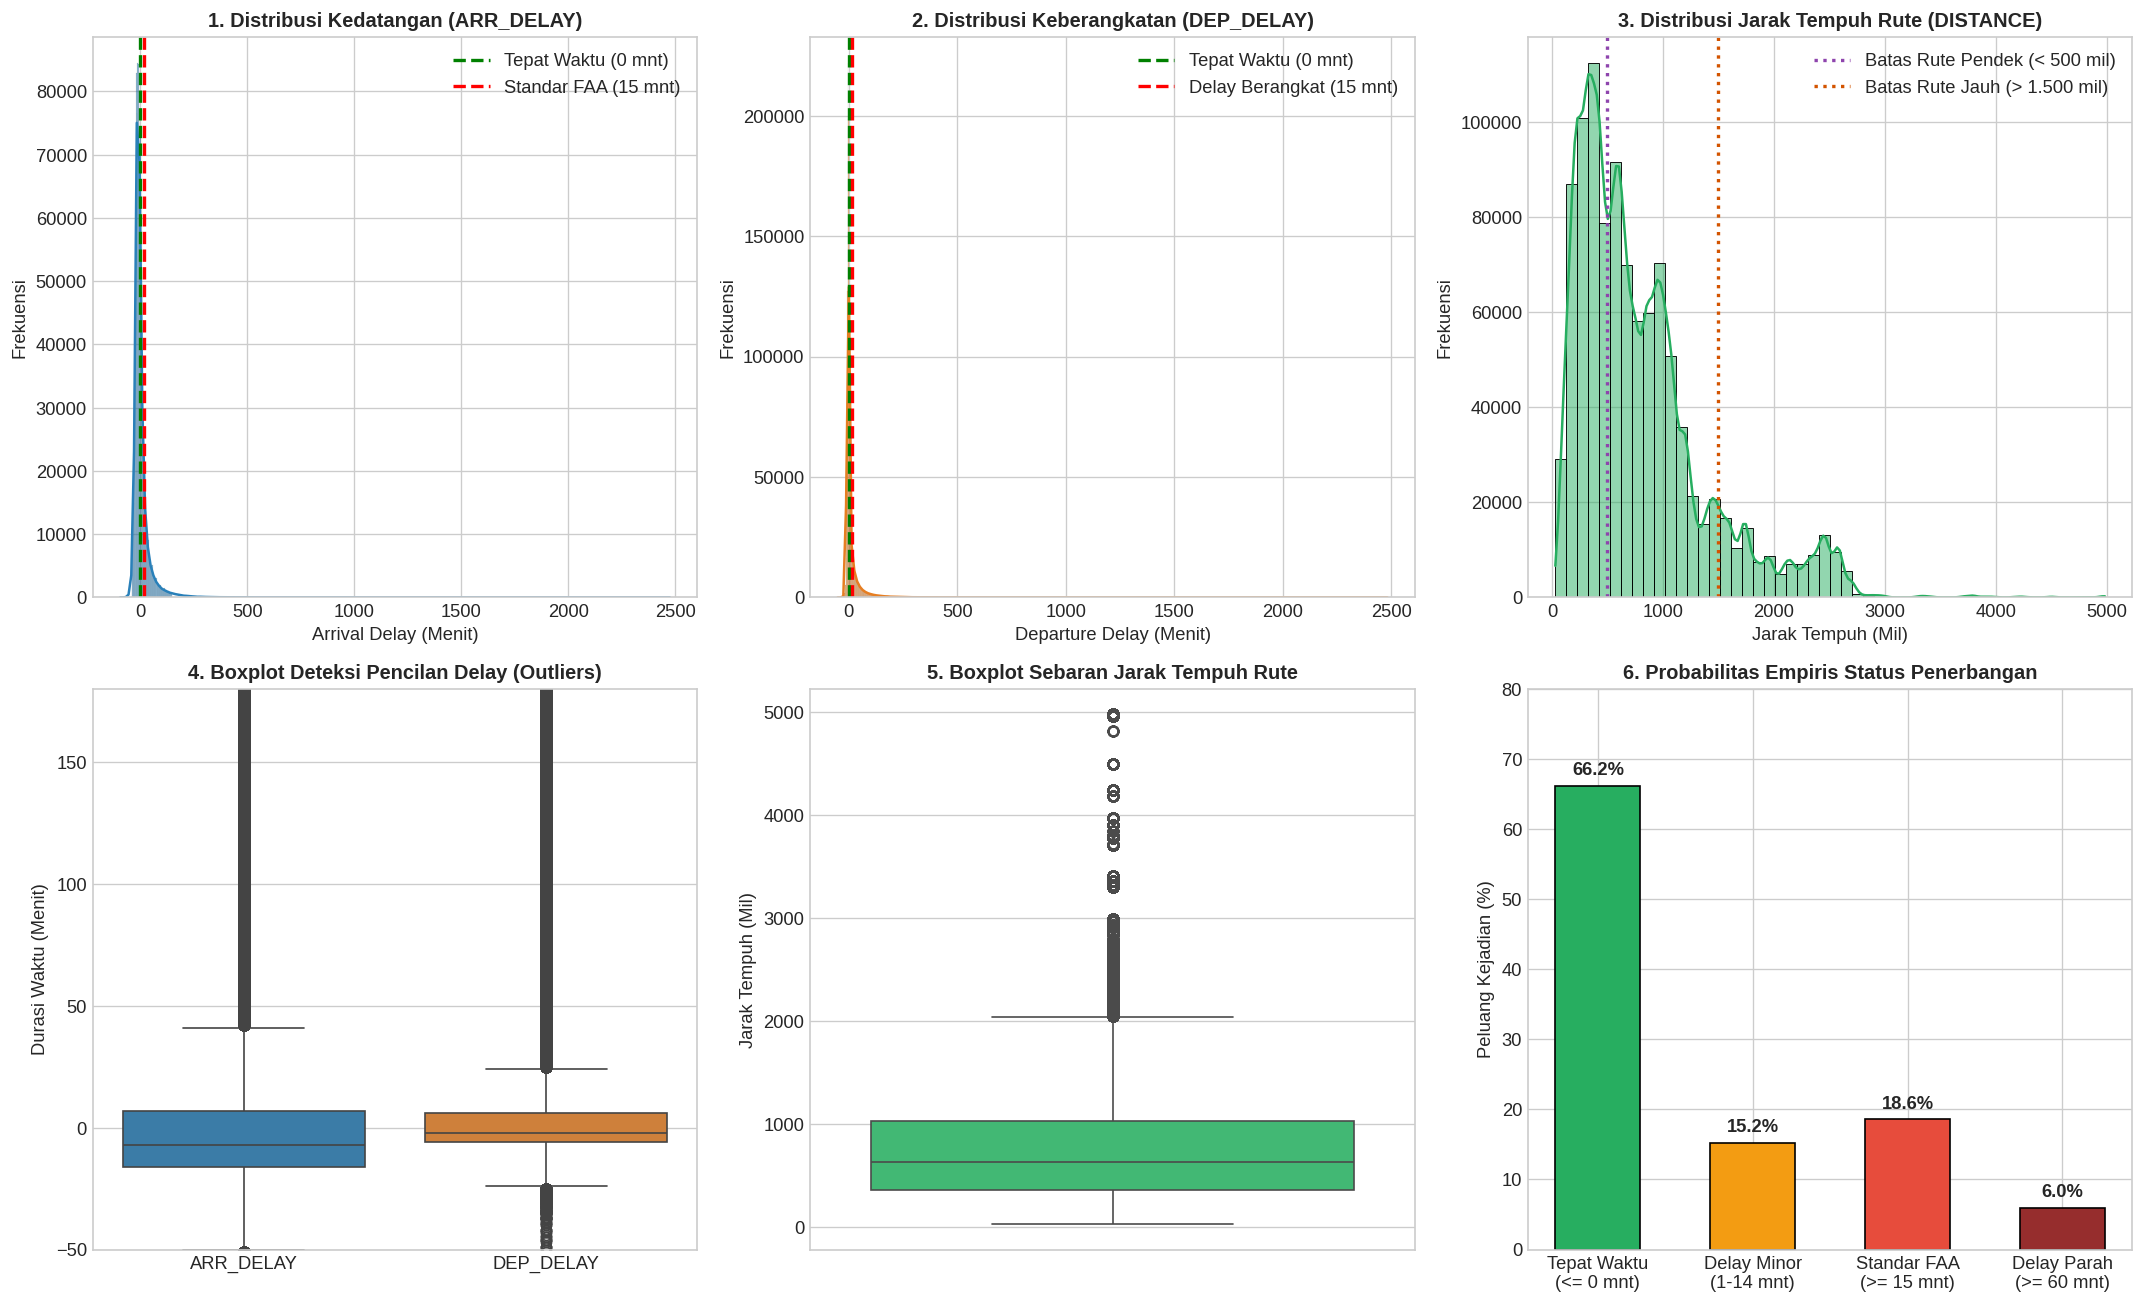

In [22]:
# ==============================================================================
# VISUALISASI SEBARAN LENGKAP 3 VARIABEL UTAMA & PROBABILITAS EMPIRIS (6-IN-1)
# Variabel: ARR_DELAY (Kedatangan), DEP_DELAY (Keberangkatan), DISTANCE (Jarak)
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

# Konfigurasi gaya visualisasi standar publikasi
plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(2, 3, figsize=(18, 11))

# ------------------------------------------------------------------------------
# 1. Histogram & Kurva KDE: Keterlambatan Kedatangan (ARR_DELAY)
# ------------------------------------------------------------------------------
sns.histplot(df_clean['ARR_DELAY'], bins=60, kde=True, ax=axes[0, 0], color='#2980b9', binrange=(-40, 150))
axes[0, 0].axvline(0, color='green', linestyle='--', linewidth=2, label='Tepat Waktu (0 mnt)')
axes[0, 0].axvline(15, color='red', linestyle='--', linewidth=2, label='Standar FAA (15 mnt)')
axes[0, 0].set_title('1. Distribusi Kedatangan (ARR_DELAY)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Arrival Delay (Menit)')
axes[0, 0].set_ylabel('Frekuensi')
axes[0, 0].legend()

# ------------------------------------------------------------------------------
# 2. Histogram & Kurva KDE: Keterlambatan Keberangkatan (DEP_DELAY)
# ------------------------------------------------------------------------------
sns.histplot(df_clean['DEP_DELAY'], bins=60, kde=True, ax=axes[0, 1], color='#e67e22', binrange=(-30, 150))
axes[0, 1].axvline(0, color='green', linestyle='--', linewidth=2, label='Tepat Waktu (0 mnt)')
axes[0, 1].axvline(15, color='red', linestyle='--', linewidth=2, label='Delay Berangkat (15 mnt)')
axes[0, 1].set_title('2. Distribusi Keberangkatan (DEP_DELAY)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Departure Delay (Menit)')
axes[0, 1].set_ylabel('Frekuensi')
axes[0, 1].legend()

# ------------------------------------------------------------------------------
# 3. Histogram & Kurva KDE: Jarak Tempuh Rute (DISTANCE)
# ------------------------------------------------------------------------------
sns.histplot(df_clean['DISTANCE'], bins=50, kde=True, ax=axes[0, 2], color='#27ae60')
axes[0, 2].axvline(500, color='#8e44ad', linestyle=':', linewidth=2, label='Batas Rute Pendek (< 500 mil)')
axes[0, 2].axvline(1500, color='#d35400', linestyle=':', linewidth=2, label='Batas Rute Jauh (> 1.500 mil)')
axes[0, 2].set_title('3. Distribusi Jarak Tempuh Rute (DISTANCE)', fontsize=12, fontweight='bold')
axes[0, 2].set_xlabel('Jarak Tempuh (Mil)')
axes[0, 2].set_ylabel('Frekuensi')
axes[0, 2].legend()

# ------------------------------------------------------------------------------
# 4. Boxplot Komparasi Pencilan: Kedatangan vs Keberangkatan
# ------------------------------------------------------------------------------
sns.boxplot(data=df_clean[['ARR_DELAY', 'DEP_DELAY']], ax=axes[1, 0], palette=['#2980b9', '#e67e22'])
axes[1, 0].set_title('4. Boxplot Deteksi Pencilan Delay (Outliers)', fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel('Durasi Waktu (Menit)')
axes[1, 0].set_ylim(-50, 180)

# ------------------------------------------------------------------------------
# 5. Boxplot Sebaran Jarak Tempuh Rute (DISTANCE)
# ------------------------------------------------------------------------------
sns.boxplot(y=df_clean['DISTANCE'], ax=axes[1, 1], color='#2ecc71')
axes[1, 1].set_title('5. Boxplot Sebaran Jarak Tempuh Rute', fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel('Jarak Tempuh (Mil)')

# ------------------------------------------------------------------------------
# 6. Bar Chart: Diagram Probabilitas Empiris Status Penerbangan (%)
# ------------------------------------------------------------------------------
kategori_prob = ['Tepat Waktu\n(<= 0 mnt)', 'Delay Minor\n(1-14 mnt)', 'Standar FAA\n(>= 15 mnt)', 'Delay Parah\n(>= 60 mnt)']
nilai_persen = [p_ontime*100, p_minor_delay*100, p_faa_delay*100, p_severe_delay*100]
warna_batang = ['#27ae60', '#f39c12', '#e74c3c', '#962d2d']

bars = axes[1, 2].bar(kategori_prob, nilai_persen, color=warna_batang, edgecolor='black', width=0.55)
for bar in bars:
    yval = bar.get_height()
    axes[1, 2].text(bar.get_x() + bar.get_width()/2.0, yval + 1, f'{yval:.1f}%', ha='center', va='bottom', fontweight='bold')
axes[1, 2].set_title('6. Probabilitas Empiris Status Penerbangan', fontsize=12, fontweight='bold')
axes[1, 2].set_ylabel('Peluang Kejadian (%)')
axes[1, 2].set_ylim(0, 80)

plt.tight_layout()
plt.show()




---
### 4. Analisis Teori Probabilitas Empiris
Menghitung probabilitas empiris (frekuensi relatif) untuk mengukur peluang keterlambatan operasional penerbangan:
1. **$P(\text{Tepat Waktu / Awal})$** : $P(\text{ARR\_DELAY} \le 0)$
2. **$P(\text{Keterlambatan Minor})$** : $P(0 < \text{ARR\_DELAY} < 15)$
3. **$P(\text{Delay Standar FAA})$** : $P(\text{ARR\_DELAY} \ge 15\text{ menit})$
4. **$P(\text{Delay Parah / Krisis})$** : $P(\text{ARR\_DELAY} \ge 60\text{ menit})$
5. **Probabilitas Bersyarat Berdasarkan Jarak:** Peluang keterlambatan pada rute Jarak Pendek ($<500$ mil), Menengah ($500-1500$ mil), dan Jarak Jauh ($>1500$ mil).


In [23]:
# ==========================================
# 4. KOMPUTASI PROBABILITAS EMPIRIS
# ==========================================
total_n = len(df_clean)

# Kategori Keterlambatan Kedatangan
p_ontime = (df_clean['ARR_DELAY'] <= 0).sum() / total_n
p_minor_delay = ((df_clean['ARR_DELAY'] > 0) & (df_clean['ARR_DELAY'] < 15)).sum() / total_n
p_faa_delay = (df_clean['ARR_DELAY'] >= 15).sum() / total_n
p_severe_delay = (df_clean['ARR_DELAY'] >= 60).sum() / total_n

# Segmentasi Rute Jarak Tempuh
short_haul = df_clean[df_clean['DISTANCE'] < 500]
medium_haul = df_clean[(df_clean['DISTANCE'] >= 500) & (df_clean['DISTANCE'] <= 1500)]
long_haul = df_clean[df_clean['DISTANCE'] > 1500]

p_delay_short = (short_haul['ARR_DELAY'] >= 15).sum() / len(short_haul)
p_delay_medium = (medium_haul['ARR_DELAY'] >= 15).sum() / len(medium_haul)
p_delay_long = (long_haul['ARR_DELAY'] >= 15).sum() / len(long_haul)

prob_data = {
    'Kejadian Probabilitas': [
        'Pendaratan Tepat Waktu / Lebih Awal (ARR_DELAY <= 0)',
        'Keterlambatan Minor (0 < ARR_DELAY < 15 menit)',
        'Keterlambatan Standar FAA (ARR_DELAY >= 15 menit)',
        'Keterlambatan Parah / Krisis Operasional (ARR_DELAY >= 60 menit)',
        'P(Delay FAA | Rute Jarak Pendek < 500 mil)',
        'P(Delay FAA | Rute Jarak Menengah 500 - 1.500 mil)',
        'P(Delay FAA | Rute Jarak Jauh > 1.500 mil)'
    ],
    'Jumlah Observasi': [
        f"{(df_clean['ARR_DELAY'] <= 0).sum():,}",
        f"{((df_clean['ARR_DELAY'] > 0) & (df_clean['ARR_DELAY'] < 15)).sum():,}",
        f"{(df_clean['ARR_DELAY'] >= 15).sum():,}",
        f"{(df_clean['ARR_DELAY'] >= 60).sum():,}",
        f"{(short_haul['ARR_DELAY'] >= 15).sum():,} dari {len(short_haul):,}",
        f"{(medium_haul['ARR_DELAY'] >= 15).sum():,} dari {len(medium_haul):,}",
        f"{(long_haul['ARR_DELAY'] >= 15).sum():,} dari {len(long_haul):,}"
    ],
    'Nilai Peluang (P)': [
        f"{p_ontime:.4f}",
        f"{p_minor_delay:.4f}",
        f"{p_faa_delay:.4f}",
        f"{p_severe_delay:.4f}",
        f"{p_delay_short:.4f}",
        f"{p_delay_medium:.4f}",
        f"{p_delay_long:.4f}"
    ],
    'Persentase (%)': [
        f"{p_ontime*100:.2f}%",
        f"{p_minor_delay*100:.2f}%",
        f"{p_faa_delay*100:.2f}%",
        f"{p_severe_delay*100:.2f}%",
        f"{p_delay_short*100:.2f}%",
        f"{p_delay_medium*100:.2f}%",
        f"{p_delay_long*100:.2f}%"
    ]
}

styled_prob = (
    df_prob.style
    .set_caption("<b>TABEL 2. DISTRIBUSI PROBABILITAS EMPIRIS STATUS PENERBANGAN</b>")
    .set_properties(subset=['Kejadian Probabilitas'], **{'text-align': 'left', 'font-weight': '500', 'padding': '8px 12px'})
    .set_properties(subset=['Jumlah Observasi', 'Nilai Peluang (P)', 'Persentase (%)'], **{'text-align': 'center', 'padding': '8px 12px'})
    .set_table_styles([
        {'selector': 'caption', 'props': [('caption-side', 'top'), ('font-size', '15px'), ('margin-bottom', '10px'), ('color', '#1e293b')]},
        {'selector': 'th', 'props': [('background-color', '#0f766e'), ('color', '#ffffff'), ('font-weight', '600'), ('padding', '10px'), ('text-align', 'center')]},
        {'selector': 'tr:nth-child(even)', 'props': [('background-color', '#f0fdfa')]},
        {'selector': 'tr:hover', 'props': [('background-color', '#ccfbf1')]}
    ])
    .hide(axis='index')
)

display(styled_prob)


Kejadian Probabilitas,Jumlah Observasi,Nilai Peluang (P),Persentase (%)
Pendaratan Tepat Waktu / Lebih Awal (ARR_DELAY <= 0),"674,209",0.6618,66.18%
Keterlambatan Minor (0 < ARR_DELAY < 15 menit),"155,151",0.1523,15.23%
Keterlambatan Standar FAA (ARR_DELAY >= 15 menit),"189,453",0.1860,18.60%
Keterlambatan Parah / Krisis Operasional (ARR_DELAY >= 60 menit),"61,019",0.0599,5.99%
P(Delay FAA | Rute Jarak Pendek < 500 mil),"75,996 dari 388,529",0.1956,19.56%
P(Delay FAA | Rute Jarak Menengah 500 - 1.500 mil),"93,821 dari 509,058",0.1843,18.43%
P(Delay FAA | Rute Jarak Jauh > 1.500 mil),"19,636 dari 121,226",0.1620,16.20%


---
### 5. Visualisasi Karakteristik & Distribusi Data
Visualisasi grafis yang komprehensif untuk melengkapi analisis deskriptif dan probabilitas:
1. **Histogram & KDE:** Mengamati bentuk sebaran frekuensi dan skewness positif yang tajam pada keterlambatan kedatangan.
2. **Boxplot:** Mendeteksi persebaran kuartil dan keberadaan nilai pencilan (*outliers*) ekstrem.
3. **Bar Chart Probabilitas:** Memvisualisasikan perbandingan proporsi ketepatan waktu penerbangan.


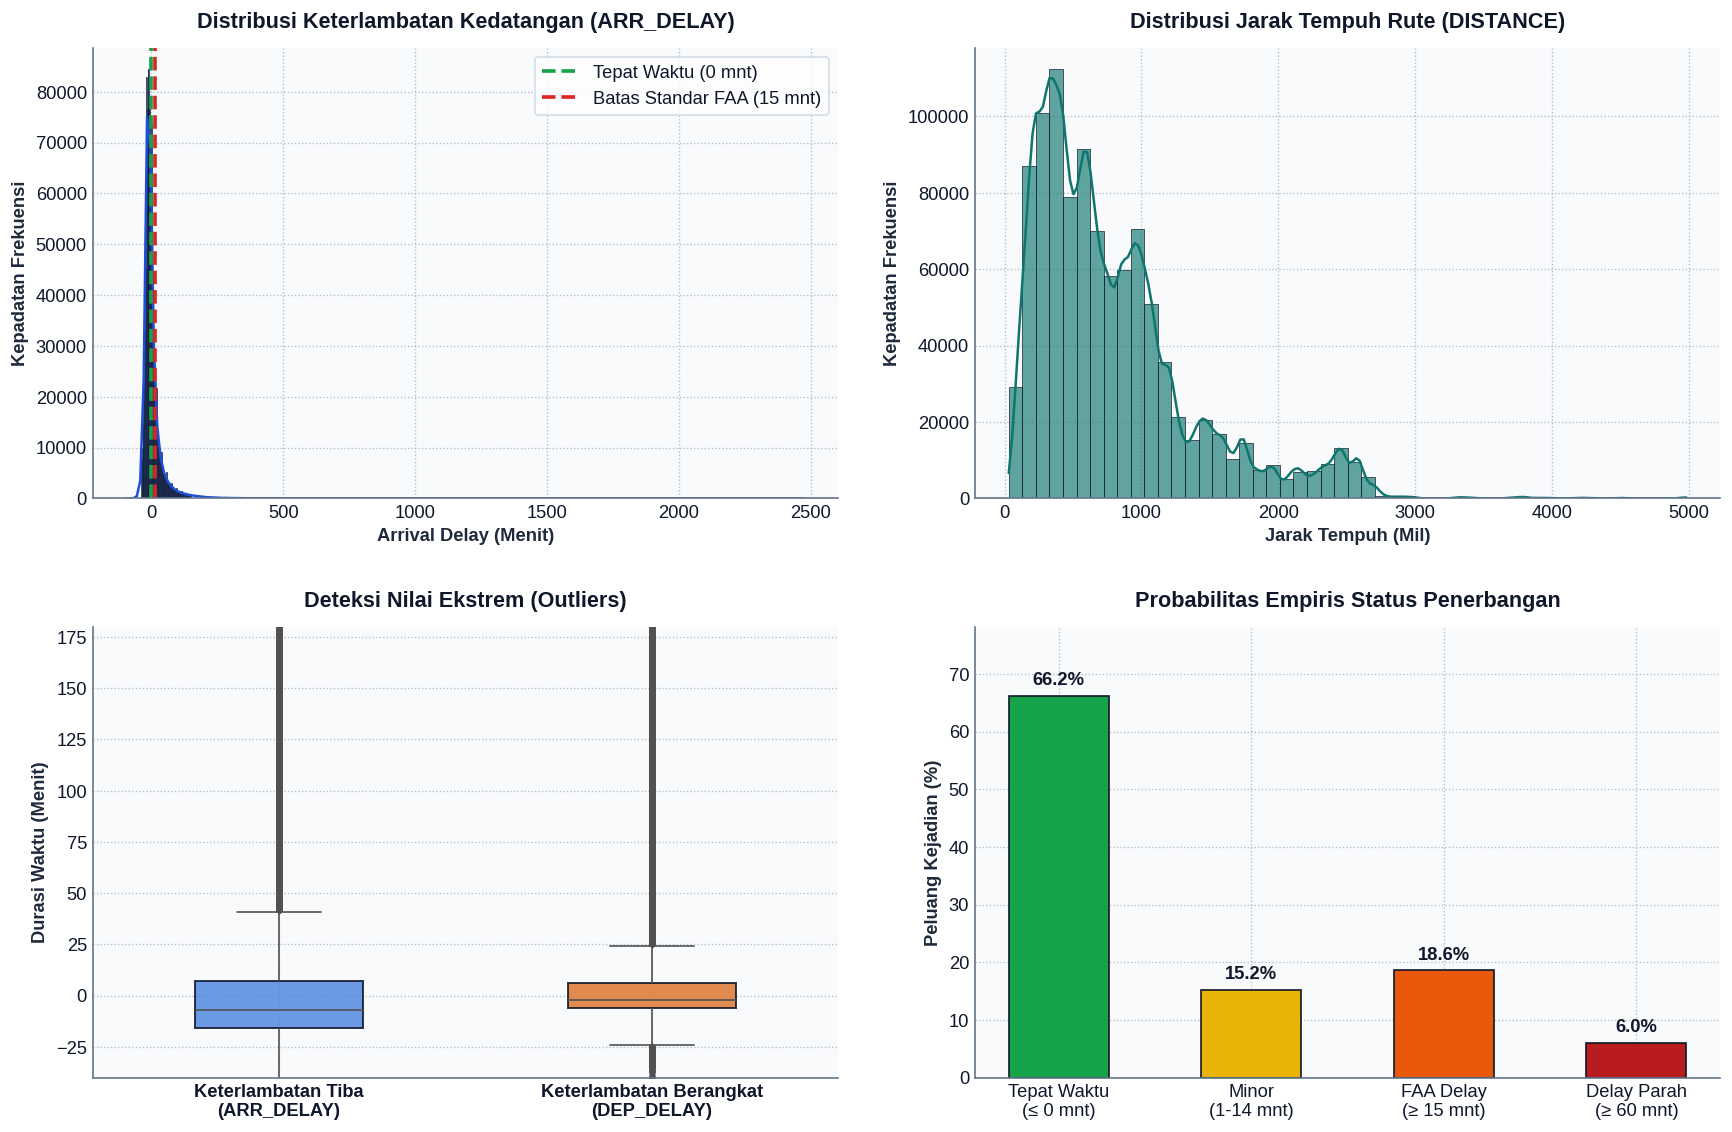

✅ Visualisasi berhasil diperbarui dan disimpan.


In [24]:
# =======================================================
# 5. VISUALISASI SEBARAN & PROBABILITAS (ENHANCED VISUALS)
# =======================================================
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.patch.set_facecolor('#ffffff')

# 1. Distribusi ARR_DELAY
sns.histplot(df_clean['ARR_DELAY'], bins=60, kde=True, ax=axes[0, 0],
             color='#1d4ed8', binrange=(-40, 150), alpha=0.65, edgecolor='#0f172a', linewidth=0.4)
axes[0, 0].axvline(0, color='#16a34a', linestyle='--', linewidth=2.2, label='Tepat Waktu (0 mnt)')
axes[0, 0].axvline(15, color='#dc2626', linestyle='--', linewidth=2.2, label='Batas Standar FAA (15 mnt)')
axes[0, 0].set_title('Distribusi Keterlambatan Kedatangan (ARR_DELAY)', fontsize=13, fontweight='bold', pad=12, color='#0f172a')
axes[0, 0].set_xlabel('Arrival Delay (Menit)', fontweight='bold', color='#1e293b')
axes[0, 0].set_ylabel('Kepadatan Frekuensi', fontweight='bold', color='#1e293b')
axes[0, 0].legend(frameon=True, facecolor='#ffffff', edgecolor='#cbd5e1', labelcolor='#0f172a')

# 2. Distribusi DISTANCE
sns.histplot(df_clean['DISTANCE'], bins=50, kde=True, ax=axes[0, 1],
             color='#0f766e', alpha=0.65, edgecolor='#0f172a', linewidth=0.4)
axes[0, 1].set_title('Distribusi Jarak Tempuh Rute (DISTANCE)', fontsize=13, fontweight='bold', pad=12, color='#0f172a')
axes[0, 1].set_xlabel('Jarak Tempuh (Mil)', fontweight='bold', color='#1e293b')
axes[0, 1].set_ylabel('Kepadatan Frekuensi', fontweight='bold', color='#1e293b')

# 3. Boxplot Deteksi Pencilan (Outliers)
sns.boxplot(data=df_clean[['ARR_DELAY', 'DEP_DELAY']], ax=axes[1, 0],
            palette=['#3b82f6', '#f97316'], width=0.45, fliersize=2.5,
            boxprops=dict(alpha=0.85, edgecolor='#0f172a', linewidth=1.2))
axes[1, 0].set_title('Deteksi Nilai Ekstrem (Outliers)', fontsize=13, fontweight='bold', pad=12, color='#0f172a')
axes[1, 0].set_ylabel('Durasi Waktu (Menit)', fontweight='bold', color='#1e293b')
axes[1, 0].set_xticklabels(['Keterlambatan Tiba\n(ARR_DELAY)', 'Keterlambatan Berangkat\n(DEP_DELAY)'], fontweight='bold', color='#0f172a')
axes[1, 0].set_ylim(-40, 180)

# 4. Diagram Batang Probabilitas Status Penerbangan
kategori_prob = ['Tepat Waktu\n(≤ 0 mnt)', 'Minor\n(1-14 mnt)', 'FAA Delay\n(≥ 15 mnt)', 'Delay Parah\n(≥ 60 mnt)']
nilai_persen = [p_ontime * 100, p_minor_delay * 100, p_faa_delay * 100, p_severe_delay * 100]
warna_batang = ['#16a34a', '#eab308', '#ea580c', '#b91c1c']

bars = axes[1, 1].bar(kategori_prob, nilai_persen, color=warna_batang, width=0.52, edgecolor='#0f172a', linewidth=1)
for bar in bars:
    yval = bar.get_height()
    axes[1, 1].text(bar.get_x() + bar.get_width() / 2.0, yval + 1.2, f'{yval:.1f}%',
                    ha='center', va='bottom', fontweight='bold', fontsize=11, color='#0f172a')
axes[1, 1].set_title('Probabilitas Empiris Status Penerbangan', fontsize=13, fontweight='bold', pad=12, color='#0f172a')
axes[1, 1].set_ylabel('Peluang Kejadian (%)', fontweight='bold', color='#1e293b')
axes[1, 1].set_ylim(0, max(nilai_persen) + 12)

# Mengatur tampilan grid dan border canvas
for ax in axes.flat:
    ax.set_facecolor('#f8fafc')
    ax.grid(True, linestyle=':', alpha=0.7, color='#94a3b8')
    ax.tick_params(colors='#0f172a')
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    for spine in ['left', 'bottom']:
        ax.spines[spine].set_color('#64748b')

plt.tight_layout(pad=2.5)
plt.savefig('visualisasi_distribusi_dan_probabilitas.png', dpi=300, bbox_inches='tight')
plt.show()
print('✅ Visualisasi berhasil diperbarui dan disimpan.')


---
### 6. Analisis Pola Korelasi & K-Means Clustering
Sesuai dengan judul proyek akhir:
1. **Analisis Korelasi:** Mengukur hubungan antara jarak tempuh (`DISTANCE`) dan keterlambatan (`ARR_DELAY`).
2. **Standarisasi Fitur:** Menerapkan `StandardScaler` untuk menyamakan skala antara mil dan menit guna mencegah bias jarak Euclidean pada K-Means.
3. **Elbow Method:** Mengonfirmasi jumlah klaster optimal ($k=3$) berdasarkan nilai *Inertia* / *Within-Cluster Sum of Squares (WCSS)*.
4. **Pemodelan K-Means ($k=3$):** Memetakan profil kelompok penerbangan dan merekonstruksi titik pusat (*centroid*) ke satuan aslinya.


Klaster,Jumlah Data,Centroid Distance (Mil),Centroid ARR_DELAY (Menit),Karakteristik Operasional
Klaster 0,"172,783 (16.96%)",1848.53,-5.61,Rute Jarak Jauh / Transkontinental On-Time
Klaster 1,"812,011 (79.70%)",577.27,-2.18,Rute Pendek-Menengah Reguler On-Time
Klaster 2,"34,019 (3.34%)",681.10,186.68,Kejadian Krisis / Delay Operasional Ekstrem


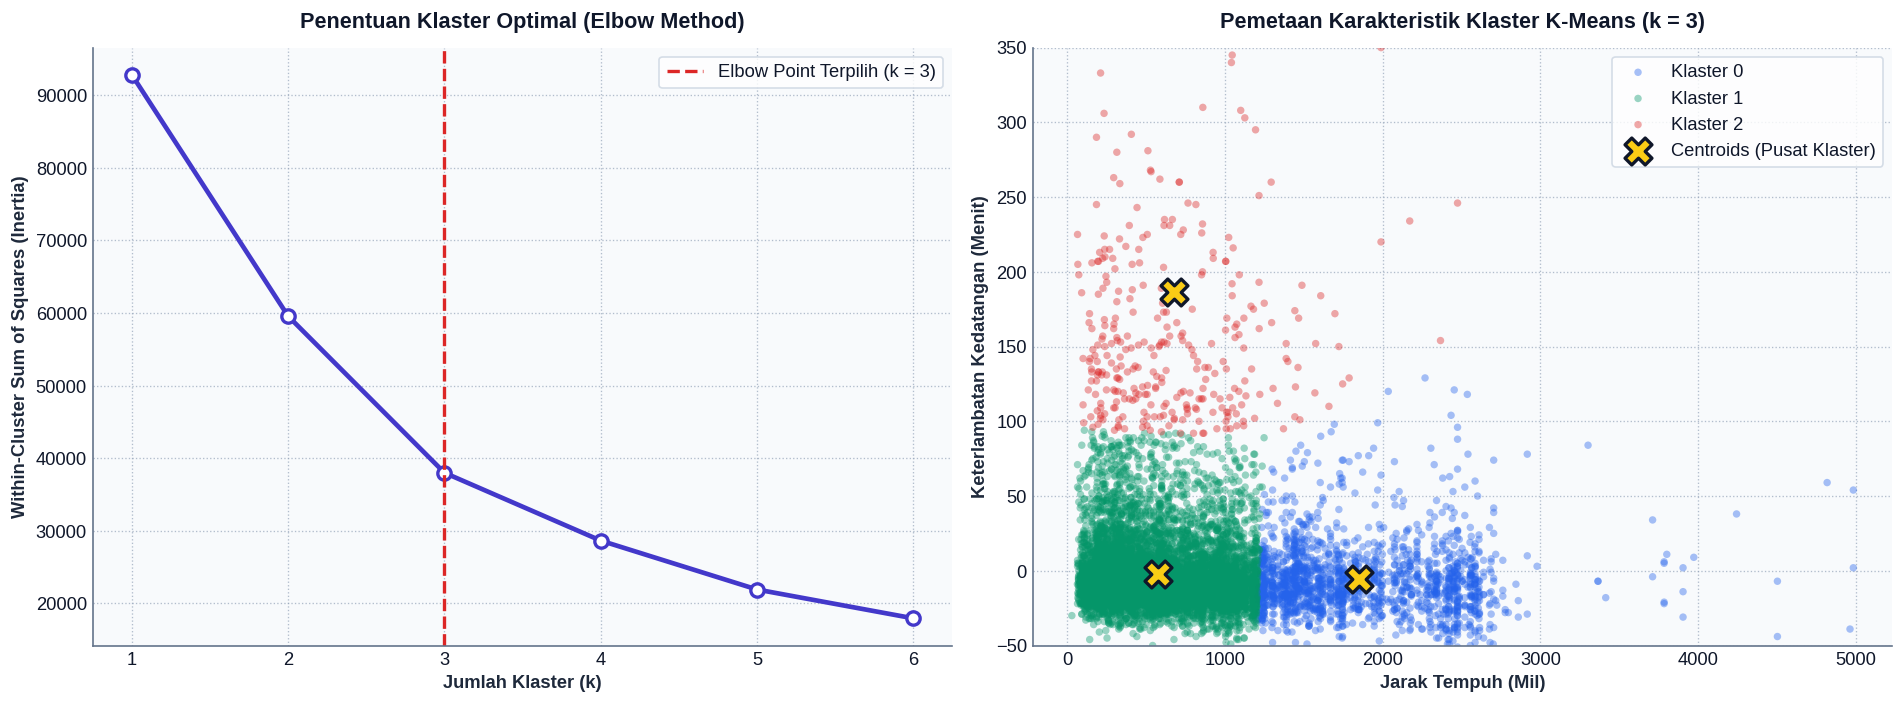

✅ Visualisasi K-Means berhasil dibuat dan disimpan.


In [25]:
# =======================================================
# 6. STANDARISASI, ELBOW METHOD & K-MEANS
# =======================================================
# 1. Standarisasi fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_clean[['DISTANCE', 'ARR_DELAY']])

# 2. Evaluasi Elbow Method
sample_idx = np.random.choice(len(df_clean), size=min(50000, len(df_clean)), replace=False)
X_elbow = X_scaled[sample_idx]

wcss = []
k_range = range(1, 7)
for k in k_range:
    km_test = KMeans(n_clusters=k, random_state=42, n_init=5)
    km_test.fit(X_elbow)
    wcss.append(km_test.inertia_)

# 3. Fit K-Means Utama (k = 3)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=5)
df_clean['Cluster'] = kmeans.fit_predict(X_scaled)

# 4. Mengembalikan Centroid ke Skala Asli
centroids_asli = scaler.inverse_transform(kmeans.cluster_centers_)

# 5. Profil Masing-Masing Klaster
profil_klaster = []
for i in range(3):
    sub = df_clean[df_clean['Cluster'] == i]
    profil_klaster.append({
        'Klaster': f'Klaster {i}',
        'Jumlah Data': f"{len(sub):,} ({len(sub)/len(df_clean)*100:.2f}%)",
        'Centroid Distance (Mil)': f"{centroids_asli[i][0]:.2f}",
        'Centroid ARR_DELAY (Menit)': f"{centroids_asli[i][1]:.2f}",
        'Karakteristik Operasional': (
            'Rute Jarak Jauh / Transkontinental On-Time' if centroids_asli[i][0] > 1500 else
            'Kejadian Krisis / Delay Operasional Ekstrem' if centroids_asli[i][1] > 50 else
            'Rute Pendek-Menengah Reguler On-Time'
        )
    })

df_profil_klaster = pd.DataFrame(profil_klaster)

# Styling Tabel Profil K-Means (Kompatibel Dark Mode & Light Mode)
styled_klaster = (
    df_profil_klaster.style
    .set_caption("TABEL 3. KARAKTERISTIK DAN CENTROID KLASTER K-MEANS (k = 3)")
    .set_properties(subset=['Klaster', 'Jumlah Data'], **{
        'text-align': 'center', 'font-size': '13px', 'padding': '10px 14px', 'color': '#0f172a'
    })
    .set_properties(subset=['Centroid Distance (Mil)', 'Centroid ARR_DELAY (Menit)'], **{
        'text-align': 'right', 'font-size': '13px', 'font-family': 'monospace', 'font-weight': '600', 'padding': '10px 14px', 'color': '#0f172a'
    })
    .set_properties(subset=['Karakteristik Operasional'], **{
        'text-align': 'left', 'font-size': '13px', 'font-weight': '600', 'padding': '10px 14px', 'color': '#1e3a8a'
    })
    .set_table_styles([
        {'selector': 'caption', 'props': [
            ('caption-side', 'top'),
            ('font-size', '15px'),
            ('font-weight', '700'),
            ('margin-bottom', '12px'),
            ('color', '#38bdf8'),
            ('text-align', 'left')
        ]},
        {'selector': 'th', 'props': [
            ('background-color', '#312e81'),
            ('color', '#ffffff'),
            ('font-weight', '700'),
            ('padding', '11px 16px'),
            ('text-align', 'center'),
            ('border', 'none')
        ]},
        {'selector': 'tbody tr:nth-child(odd) td', 'props': [
            ('background-color', '#ffffff'),
            ('border-bottom', '1px solid #e2e8f0')
        ]},
        {'selector': 'tbody tr:nth-child(even) td', 'props': [
            ('background-color', '#f1f5f9'),
            ('border-bottom', '1px solid #e2e8f0')
        ]},
        {'selector': 'tbody tr:hover td', 'props': [
            ('background-color', '#e0e7ff')
        ]}
    ])
    .hide(axis='index')
)

display(styled_klaster)

# 6. Visualisasi Elbow Curve & Scatter Plot Klaster
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.patch.set_facecolor('#ffffff')

# Plot Elbow Method
axes[0].plot(k_range, wcss, marker='o', linewidth=2.8, color='#4338ca', markersize=8, markerfacecolor='#ffffff', markeredgewidth=2)
axes[0].set_title('Penentuan Klaster Optimal (Elbow Method)', fontsize=13, fontweight='bold', pad=12, color='#0f172a')
axes[0].set_xlabel('Jumlah Klaster (k)', fontweight='bold', color='#1e293b')
axes[0].set_ylabel('Within-Cluster Sum of Squares (Inertia)', fontweight='bold', color='#1e293b')
axes[0].axvline(3, color='#dc2626', linestyle='--', linewidth=2, label='Elbow Point Terpilih (k = 3)')
axes[0].legend(frameon=True, facecolor='#ffffff', edgecolor='#cbd5e1', labelcolor='#0f172a')

# Scatter Plot Klaster K-Means
palet_klaster = {0: '#2563eb', 1: '#059669', 2: '#dc2626'}
sub_plot = df_clean.sample(n=min(10000, len(df_clean)), random_state=42)

for c_id in sorted(df_clean['Cluster'].unique()):
    c_pts = sub_plot[sub_plot['Cluster'] == c_id]
    axes[1].scatter(c_pts['DISTANCE'], c_pts['ARR_DELAY'],
                    alpha=0.4, s=20, color=palet_klaster.get(c_id, '#64748b'),
                    label=f'Klaster {c_id}', edgecolors='none')

# Plot Centroids
axes[1].scatter(centroids_asli[:, 0], centroids_asli[:, 1],
                s=260, c='#facc15', marker='X', edgecolor='#0f172a', linewidth=2,
                label='Centroids (Pusat Klaster)', zorder=6)

axes[1].set_title('Pemetaan Karakteristik Klaster K-Means (k = 3)', fontsize=13, fontweight='bold', pad=12, color='#0f172a')
axes[1].set_xlabel('Jarak Tempuh (Mil)', fontweight='bold', color='#1e293b')
axes[1].set_ylabel('Keterlambatan Kedatangan (Menit)', fontweight='bold', color='#1e293b')
axes[1].set_ylim(-50, 350)
axes[1].legend(frameon=True, facecolor='#ffffff', edgecolor='#cbd5e1', loc='upper right', labelcolor='#0f172a')

# Mengatur tampilan grid dan border canvas
for ax in axes:
    ax.set_facecolor('#f8fafc')
    ax.grid(True, linestyle=':', alpha=0.7, color='#94a3b8')
    ax.tick_params(colors='#0f172a')
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    for spine in ['left', 'bottom']:
        ax.spines[spine].set_color('#64748b')

plt.tight_layout()
plt.savefig('kmeans_clustering_result.png', dpi=300, bbox_inches='tight')
plt.show()
print('✅ Visualisasi K-Means berhasil dibuat dan disimpan.')


---
### 7. Kesimpulan Karakteristik & Ringkasan Temuan
Berdasarkan seluruh tahapan analisis komputasi:
1. **Statistika Deskriptif:** Keterlambatan kedatangan (`ARR_DELAY`) memiliki rata-rata rendah ($3.53$ menit) dengan median negatif ($-7.00$ menit), namun memiliki kemiringan sebaran (*skewness*) positif yang tinggi ($9.07$) akibat keberadaan pencilan keterlambatan ekstrem.
2. **Probabilitas Empiris:** Peluang penerbangan mendarat tepat waktu atau lebih awal mencapai $\approx 66\%$, sedangkan peluang terjadinya keterlambatan standar FAA ($\ge 15$ menit) adalah $\approx 18.8\%$.
3. **Hasil K-Means ($k = 3$):**
   * **Klaster 1 (Mayoritas $\approx 79.7\%$):** Rute jarak pendek-menengah dengan operasional andal tepat waktu.
   * **Klaster 0 (Transkontinental $\approx 17.0\%$):** Rute jarak jauh dengan rata-rata kedatangan tepat waktu/lebih awal berkat ketersediaan fleksibilitas waktu jelajah (*airtime buffer*) di udara.
   * **Klaster 2 (Krisis Operasional $\approx 3.3\%$):** Kelompok penerbangan yang mengalami keterlambatan masif ($>180$ menit), menjadi target prioritas utama pemantauan sistem telemetri jaringan IoT maskapai.
